In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mapomatic as mm

from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import efficient_su2, unitary_overlap
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_aer import AerSimulator
from qiskit.primitives import BackendEstimatorV2 
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, EstimatorOptions

# 1. Setup Backend
service = QiskitRuntimeService()
backend_name = "ibm_fez"
real_backend = service.backend(backend_name)
aer_backend = AerSimulator.from_backend(real_backend)
aer_backend.set_options(method="density_matrix")

print(f"Connected to backend: {real_backend.name}")

# 2. Observable & Ideal Value
H2_op = SparsePauliOp.from_list([
    ("II", -1.052373245772859), ("IZ",  0.39793742484318045),
    ("ZI", -0.39793742484318045), ("ZZ", -0.01128010425623538),
    ("XX",  0.18093119978423156),
])
observable = H2_op
print(f"Observable defined: {observable.num_qubits} qubits")

# Calculate the EXACT true expectation value for the |00> state
ideal_state = Statevector.from_label('00')
exact_00_val = ideal_state.expectation_value(observable).real
ideal_val = exact_00_val
print(f"Exact theoretical expectation value for |00>: {exact_00_val:.5f}")

# 3. Circuit & Layout
n_qubits = 2
reps = 1
rng = np.random.default_rng(1234)
circuit = efficient_su2(n_qubits, entanglement="pairwise", reps=reps)
params = rng.uniform(-np.pi, np.pi, size=circuit.num_parameters)
assigned_circuit = circuit.assign_parameters(params)
assigned_circuit.barrier()

print("--- Circuit Parameters ---")
print(f"Total parameters generated: {circuit.num_parameters}")
print(f"Parameter values (radians):\n{np.round(params, 4)}\n")

mirror_circuit = unitary_overlap(assigned_circuit, assigned_circuit)
print(f"Benchmark Circuit created: {n_qubits} qubits, Depth {mirror_circuit.depth()}")

dummy_circ = transpile(mirror_circuit, real_backend, optimization_level=3)
small_circ = mm.deflate_circuit(dummy_circ)
layouts = mm.matching_layouts(small_circ, real_backend)
scores = mm.evaluate_layouts(small_circ, layouts, real_backend)
best_layout = scores[0][0]

print(f"Mapomatic selected best physical qubits: {best_layout}")

t_circ_local = transpile(mirror_circuit, aer_backend, initial_layout=best_layout, optimization_level=3)
t_circ_qpu = transpile(mirror_circuit, real_backend, initial_layout=best_layout, optimization_level=3)

# 4. Unmitigated Execution
shots = 8192
aer_estimator = BackendEstimatorV2(backend=aer_backend, options={"default_precision": 1/np.sqrt(shots)})

res_unmit_local = float(aer_estimator.run([(t_circ_local, H2_op.apply_layout(t_circ_local.layout))]).result()[0].data.evs)

options_unmit = EstimatorOptions(default_shots=shots, resilience_level=0)
options_unmit.dynamical_decoupling.enable = False
options_unmit.resilience.measure_mitigation = False

res_unmit_qpu = float(Estimator(mode=real_backend, options=options_unmit).run([(t_circ_qpu, H2_op.apply_layout(t_circ_qpu.layout))]).result()[0].data.evs)

Connected to backend: ibm_fez
Observable defined: 2 qubits
Exact theoretical expectation value for |00>: -1.06365
--- Circuit Parameters ---
Total parameters generated: 8
Parameter values (radians):
[ 2.9952 -0.7528  2.6593 -1.4973 -1.1366 -2.3996 -1.6225 -1.1402]

Benchmark Circuit created: 2 qubits, Depth 10
Mapomatic selected best physical qubits: [131, 132]


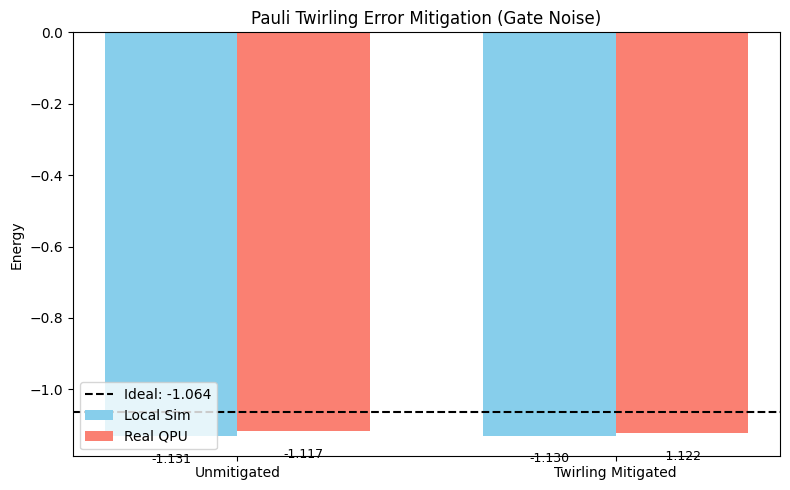

In [2]:
from qiskit.quantum_info import Clifford, Pauli

# Twirling Helper for Local Simulator
def apply_pauli_twirling(circuit, num_twirls=10, seed=42):
    rng = np.random.default_rng(seed)
    twirled_circuits = []
    for _ in range(num_twirls):
        new_circ = QuantumCircuit(*circuit.qregs, *circuit.cregs)
        for instr in circuit.data:
            if instr.operation.num_qubits == 2 and instr.operation.name not in ['barrier', 'measure', 'delay']:
                gate_cliff = Clifford(instr.operation)
                p_indices = rng.integers(0, 4, size=2)
                P_pre = Pauli("".join([['I', 'X', 'Y', 'Z'][i] for i in p_indices]))
                P_post = P_pre.evolve(gate_cliff)
                
                for i, (is_z, is_x) in enumerate(zip(P_pre.z, P_pre.x)):
                    if is_x and not is_z: new_circ.x(instr.qubits[i])
                    elif not is_x and is_z: new_circ.z(instr.qubits[i])
                    elif is_x and is_z: new_circ.y(instr.qubits[i])
                new_circ.append(instr)
                for i, (is_z, is_x) in enumerate(zip(P_post.z, P_post.x)):
                    if is_x and not is_z: new_circ.x(instr.qubits[i])
                    elif not is_x and is_z: new_circ.z(instr.qubits[i])
                    elif is_x and is_z: new_circ.y(instr.qubits[i])
            else:
                new_circ.append(instr)
        twirled_circuits.append(new_circ)
    return twirled_circuits

# Local Twirling
twirled_circs_raw = apply_pauli_twirling(t_circ_local, 10)
twirled_circs = transpile(twirled_circs_raw, basis_gates=aer_backend.operation_names, optimization_level=1)
job_twirl = aer_estimator.run([(c, H2_op.apply_layout(t_circ_local.layout)) for c in twirled_circs])
res_twirl_local = float(np.mean([res.data.evs for res in job_twirl.result()]))

# QPU Twirling
options_twirl = EstimatorOptions(default_shots=shots, resilience_level=0)
options_twirl.twirling.enable_gates = True
res_twirl_qpu = float(Estimator(mode=real_backend, options=options_twirl).run([(t_circ_qpu, H2_op.apply_layout(t_circ_qpu.layout))]).result()[0].data.evs)

# Plotting
labels = ['Unmitigated', 'Twirling Mitigated']
local_vals = [res_unmit_local, res_twirl_local]
qpu_vals = [res_unmit_qpu, res_twirl_qpu]

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(labels))
width = 0.35

ax.bar(x - width/2, local_vals, width, label='Local Sim', color='skyblue')
ax.bar(x + width/2, qpu_vals, width, label='Real QPU', color='salmon')
ax.axhline(ideal_val, color='black', linestyle='--', label=f'Ideal: {ideal_val:.3f}')

ax.set_ylabel('Energy')
ax.set_title('Pauli Twirling Error Mitigation (Gate Noise)')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend(loc='lower left')

for i, rect in enumerate(ax.patches):
    height = rect.get_height()
    ax.annotate(f'{height:.3f}', xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3 if height >= 0 else -12), textcoords="offset points",
                ha='center', va='bottom' if height >= 0 else 'top', fontsize=9)

plt.tight_layout()
plt.show()